## VGG16 Customized Cost Function

In [8]:
import argparse
import os
import time
import shutil

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torch.backends.cudnn as cudnn

    

import torchvision
import torchvision.transforms as transforms

from models import *   # bring everything in the folder models

global best_prec
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

print('=> Building model...')
    
    
batch_size = 128

model_name = "vgg16"
model = VGG16()

        

normalize = transforms.Normalize(mean=[0.491, 0.482, 0.447], std=[0.247, 0.243, 0.262])


train_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        normalize,
    ]))
trainloader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)


test_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transforms.Compose([
        transforms.ToTensor(),
        normalize,
    ]))

testloader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)


print_freq = 100 # every 100 batches, accuracy printed. Here, each batch includes "batch_size" data points
# CIFAR10 has 50,000 training data, and 10,000 validation data.

def train(trainloader, model, criterion, optimizer, epoch):
    batch_time = AverageMeter()   ## at the begining of each epoch, this should be reset
    data_time = AverageMeter()
    losses = AverageMeter()
    top1 = AverageMeter()

    model.train()

    end = time.time()  # measure current time
    
    for i, (input, target) in enumerate(trainloader):
        # measure data loading time
        data_time.update(time.time() - end)  # data loading time

        input, target = input.to(device), target.to(device)

        # compute output
        output = model(input)
        loss = criterion(output, target)

        # measure accuracy and record loss
        prec = accuracy(output, target)[0]
        losses.update(loss.item(), input.size(0))
        top1.update(prec.item(), input.size(0))

        # compute gradient and do SGD step
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # measure elapsed time
        batch_time.update(time.time() - end) # time spent to process one batch
        end = time.time()


        if i % print_freq == 0:
            print('Epoch: [{0}][{1}/{2}]\t'
                  'Time {batch_time.val:.3f} ({batch_time.avg:.3f})\t'
                  'Data {data_time.val:.3f} ({data_time.avg:.3f})\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec {top1.val:.3f}% ({top1.avg:.3f}%)'.format(
                   epoch, i, len(trainloader), batch_time=batch_time,
                   data_time=data_time, loss=losses, top1=top1))

            

def validate(val_loader, model, criterion ):
    batch_time = AverageMeter()
    losses = AverageMeter()
    top1 = AverageMeter()

    # switch to evaluate mode
    model.eval()

    end = time.time()
    with torch.no_grad():
        for i, (input, target) in enumerate(val_loader):
         
            input, target = input.to(device), target.to(device)

            # compute output
            output = model(input)
            loss = criterion(output, target)

            # measure accuracy and record loss
            prec = accuracy(output, target)[0]
            losses.update(loss.item(), input.size(0))
            top1.update(prec.item(), input.size(0))

            # measure elapsed time
            batch_time.update(time.time() - end)
            end = time.time()

            if i % print_freq == 0:  # This line shows how frequently print out the status. e.g., i%5 => every 5 batch, prints out
                print('Test: [{0}/{1}]\t'
                  'Time {batch_time.val:.3f} ({batch_time.avg:.3f})\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec {top1.val:.3f}% ({top1.avg:.3f}%)'.format(
                   i, len(val_loader), batch_time=batch_time, loss=losses,
                   top1=top1))

    print(' * Prec {top1.avg:.3f}% '.format(top1=top1))
    return top1.avg


def accuracy(output, target, topk=(1,5)):
    """Computes the precision@k for the specified values of k"""
    maxk = max(topk) # 5
    batch_size = target.size(0) # 128

    _, pred = output.topk(maxk, 1, True, True) # topk(k, dim=None, largest=True, sorted=True)
                                    # will output (max value, its index)
    pred = pred.t()               # transpose
    correct = pred.eq(target.view(1, -1).expand_as(pred))   # "-1": calculate automatically

    res = []
    for k in topk: # 1, 5
        correct_k = correct[:k].reshape(-1).float().sum(0)  # view(-1): make a flattened 1D tensor
        res.append(correct_k.mul_(100.0 / batch_size))   # correct: size of [maxk, batch_size]
    return res


class AverageMeter(object):
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n    ## n is impact factor
        self.count += n
        self.avg = self.sum / self.count

        
def save_checkpoint(state, is_best, fdir):
    filepath = os.path.join(fdir, 'checkpoint.pth')
    torch.save(state, filepath)
    if is_best:
        shutil.copyfile(filepath, os.path.join(fdir, 'model_best.pth.tar'))


def adjust_learning_rate(optimizer, epoch):
    """For resnet, the lr starts from 0.1, and is divided by 10 at 80 and 120 epochs"""
    adjust_list = [150, 225]
    if epoch in adjust_list:
        for param_group in optimizer.param_groups:
            param_group['lr'] = param_group['lr'] * 0.1 

#model = nn.DataParallel(model).cuda()
#all_params = checkpoint['state_dict']
#model.load_state_dict(all_params, strict=False)
#criterion = nn.CrossEntropyLoss().cuda()
#validate(testloader, model, criterion)

=> Building model...


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.49392712..1.5658436].


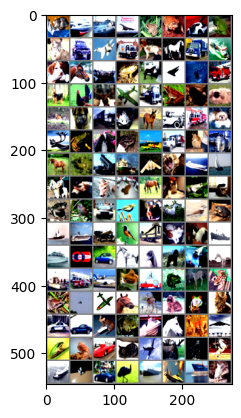

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# functions to show an image

def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

# get some random training images
dataiter = iter(testloader)
images, labels = next(dataiter) ## If you run this line, the next data batch is called subsequently.

# show images
imshow(torchvision.utils.make_grid(images))

## Step 1: Initial Baseline Evaluation (Gamma = 0)
Evaluate the baseline HW3 pretrained VGG16 model, compute the baseline test accuracy, and measure the initial absolute sum of the first conv layer's weights.

In [10]:
# Load the pretrained HW3 checkpoint
fdir = 'result/' + str(model_name) + '/model_best.pth.tar'
checkpoint = torch.load(fdir, map_location=device)
model.load_state_dict(checkpoint['state_dict'])
model.eval()
model.to(device)

criterion = nn.CrossEntropyLoss().to(device)

# 1. Baseline Test Accuracy
base_acc = validate(testloader, model, criterion)

# 2. Baseline Conv1 weight absolute sum
# Note: First conv layer is model.features[0] in this VGG16 architecture
base_conv1_abs_sum = model.features[0].weight.abs().sum().item()

print('=' * 50)
print('Step 1 (Baseline - Gamma = 0):')
print(f'Test Accuracy: {base_acc:.2f}%')
print(f'Conv1 Weight Absolute Sum: {base_conv1_abs_sum:.4f}')
print('=' * 50)


Test: [0/79]	Time 2.691 (2.691)	Loss 0.2303 (0.2303)	Prec 94.531% (94.531%)
 * Prec 93.200% 
Step 1 (Baseline - Gamma = 0):
Test Accuracy: 93.20%
Conv1 Weight Absolute Sum: 98.9487


## Customized Training Function
The loss function is formulated as:
$$\text{loss} = \text{loss}_1 + \gamma \times \text{loss}_2$$
where $\text{loss}_1 = \text{CrossEntropyLoss}$ and $\text{loss}_2 = \sum |W_{conv1}|$.

In [ ]:
def train_custom_loss(trainloader, testloader, gamma, n_epochs=5, lr=0.01):
    # Always reload fresh from the clean Step 1 checkpoint
    net = VGG16().to(device)
    ckpt = torch.load(fdir, map_location=device)
    net.load_state_dict(ckpt['state_dict'])
    
    criterion = nn.CrossEntropyLoss().to(device)
    optimizer = torch.optim.SGD(net.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)
    
    print(f"\n=> Training with gamma = {gamma} for {n_epochs} epochs (lr={lr})...")
    
    for epoch in range(n_epochs):
        net.train()
        train_loss = 0.0
        train_loss1 = 0.0
        train_loss2 = 0.0
        
        for data, target in trainloader:
            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            
            output = net(data)
            
            loss1 = criterion(output, target)
            # Regularization on first conv layer only: net.features[0]
            loss2 = net.features[0].weight.abs().sum()
            
            loss = loss1 + gamma * loss2
            
            loss.backward()
            optimizer.step()
            
            train_loss1 += loss1.item() * data.size(0)
            train_loss2 += loss2.item() * data.size(0)
            train_loss  += loss.item() * data.size(0)
            
        train_loss1 /= len(trainloader.dataset)
        train_loss2 /= len(trainloader.dataset)
        train_loss  /= len(trainloader.dataset)
        
        print(f'Epoch: [{epoch+1}/{n_epochs}]\tLoss1: {train_loss1:.4f}\tLoss2: {train_loss2:.4f}\tTotal Loss: {train_loss:.4f}')
        
    net.eval()
    test_acc = validate(testloader, net, criterion)
    conv1_sum = net.features[0].weight.abs().sum().item()
    
    return test_acc, conv1_sum

## Step 2: New Loss Term ($\gamma = 1.0$)
Train for a fixed number of epochs starting from the Step 1 baseline model using $\gamma = 1.0$.

In [12]:
# Fixed training hyperparameters for fair comparison across Step 2 and Step 3
FIXED_EPOCHS = 5
FIXED_LR = 0.01

acc_g1, sum_g1 = train_custom_loss(
    trainloader, testloader, 
    gamma=1.0, 
    n_epochs=FIXED_EPOCHS, 
    lr=FIXED_LR
)

print('=' * 50)
print('Step 2 (Gamma = 1.0):')
print(f'Test Accuracy: {acc_g1:.2f}%')
print(f'Conv1 Weight Absolute Sum: {sum_g1:.4f}')
print('=' * 50)


=> Training with gamma = 1.0 for 5 epochs (lr=0.01)...
Epoch: [1/5]	Loss1: 1.2130	Loss2: 23.6318	Total Loss: 24.8449
Epoch: [2/5]	Loss1: 0.7143	Loss2: 21.5488	Total Loss: 22.2631
Epoch: [3/5]	Loss1: 0.6135	Loss2: 20.9512	Total Loss: 21.5648
Epoch: [4/5]	Loss1: 0.5250	Loss2: 20.6570	Total Loss: 21.1820
Epoch: [5/5]	Loss1: 0.4663	Loss2: 20.4432	Total Loss: 20.9095
Test: [0/79]	Time 2.699 (2.699)	Loss 0.5673 (0.5673)	Prec 82.812% (82.812%)
 * Prec 79.220% 
Step 2 (Gamma = 1.0):
Test Accuracy: 79.22%
Conv1 Weight Absolute Sum: 19.8882


## Step 3: Fine-Tuning the Regularization Factor $\gamma$
Sweep $\gamma$ across multiple orders of magnitude (e.g., $10^{-4}, 10^{-3}, 10^{-2}, 0.05, 0.1$) starting each run from the Step 1 baseline model using the identical settings. Select the optimal $\gamma$ that keeps accuracy $\ge 80\%$ while maximizing the reduction of the first conv layer's weight absolute sum.

In [13]:
# Candidate gammas across several orders of magnitude
gammas = [1e-4, 1e-3, 1e-2, 0.05, 0.1]
results = {}

for g in gammas:
    acc_g, sum_g = train_custom_loss(
        trainloader, testloader, 
        gamma=g, 
        n_epochs=FIXED_EPOCHS, 
        lr=FIXED_LR
    )
    results[g] = {'accuracy': acc_g, 'conv1_abs_sum': sum_g}
    print(f'Done gamma={g}: Test Acc={acc_g:.2f}%, Conv1 Sum={sum_g:.4f}')

# Find optimal gamma: Acc >= 80% that minimizes Conv1 weight absolute sum
valid_candidates = {g: res for g, res in results.items() if res['accuracy'] >= 80.0}

if valid_candidates:
    optimal_gamma = min(valid_candidates.keys(), key=lambda g: valid_candidates[g]['conv1_abs_sum'])
else:
    # Fallback to the run with highest accuracy if all are below 80%
    optimal_gamma = max(results.keys(), key=lambda g: results[g]['accuracy'])

print('=' * 50)
print(f'Optimal Gamma: {optimal_gamma}')
print(f"Test Accuracy: {results[optimal_gamma]['accuracy']:.2f}%")
print(f"Conv1 Weight Absolute Sum: {results[optimal_gamma]['conv1_abs_sum']:.4f}")
print('=' * 50)


=> Training with gamma = 0.0001 for 5 epochs (lr=0.01)...
Epoch: [1/5]	Loss1: 0.1274	Loss2: 97.7971	Total Loss: 0.1372
Epoch: [2/5]	Loss1: 0.1114	Loss2: 95.6419	Total Loss: 0.1210
Epoch: [3/5]	Loss1: 0.1002	Loss2: 93.5359	Total Loss: 0.1096
Epoch: [4/5]	Loss1: 0.0962	Loss2: 91.6653	Total Loss: 0.1053
Epoch: [5/5]	Loss1: 0.0922	Loss2: 89.9276	Total Loss: 0.1012
Test: [0/79]	Time 1.846 (1.846)	Loss 0.3350 (0.3350)	Prec 89.844% (89.844%)
 * Prec 89.200% 
Done gamma=0.0001: Test Acc=89.20%, Conv1 Sum=89.2236

=> Training with gamma = 0.001 for 5 epochs (lr=0.01)...
Epoch: [1/5]	Loss1: 0.1322	Loss2: 79.7663	Total Loss: 0.2120
Epoch: [2/5]	Loss1: 0.1157	Loss2: 58.3051	Total Loss: 0.1740
Epoch: [3/5]	Loss1: 0.1194	Loss2: 49.4209	Total Loss: 0.1688
Epoch: [4/5]	Loss1: 0.1108	Loss2: 44.1535	Total Loss: 0.1550
Epoch: [5/5]	Loss1: 0.1044	Loss2: 41.5673	Total Loss: 0.1460
Test: [0/79]	Time 2.089 (2.089)	Loss 0.2920 (0.2920)	Prec 89.844% (89.844%)
 * Prec 88.900% 
Done gamma=0.001: Test Acc=88.90%

## Step 4: Summary Results Table

In [17]:
import pandas as pd

table_data = [
    {
        "Case": "1. Initial version",
        "Cost function": "loss1",
        "Test accuracy (%)": f"{base_acc:.2f}",
        "Conv1 weight abs sum": f"{base_conv1_abs_sum:.4f}"
    },
    {
        "Case": "2. New loss term (γ = 1)",
        "Cost function": "loss1 + loss2",
        "Test accuracy (%)": f"{acc_g1:.2f}",
        "Conv1 weight abs sum": f"{sum_g1:.4f}"
    },
    {
        "Case": "3. Fine-tuned (optimal γ)",
        "Cost function": f"loss1 + {optimal_gamma} × loss2",
        "Test accuracy (%)": f"{results[optimal_gamma]['accuracy']:.2f}",
        "Conv1 weight abs sum": f"{results[optimal_gamma]['conv1_abs_sum']:.4f}"
    }
]

# Add candidate trials to the breakdown
for g in gammas:
    table_data.append({
        "Case": f"   Trial (γ = {g})",
        "Cost function": f"loss1 + {g} × loss2",
        "Test accuracy (%)": f"{results[g]['accuracy']:.2f}",
        "Conv1 weight abs sum": f"{results[g]['conv1_abs_sum']:.4f}"
    })

summary_df = pd.DataFrame(table_data)
display(summary_df)

,Case,Cost function,Test accuracy (%),Conv1 weight abs sum
0,1. Initial version,loss1,93.20,98.9487
1,2. New loss term (γ = 1),loss1 + loss2,79.22,19.8882
2,3. Fine-tuned (optimal γ),loss1 + 0.05 × loss2,80.10,4.8724
3,Trial (γ = 0.0001),loss1 + 0.0001 × loss2,89.20,89.2236
4,Trial (γ = 0.001),loss1 + 0.001 × loss2,88.90,40.2521
5,Trial (γ = 0.01),loss1 + 0.01 × loss2,86.05,11.7652
6,Trial (γ = 0.05),loss1 + 0.05 × loss2,80.10,4.8724
7,Trial (γ = 0.1),loss1 + 0.1 × loss2,78.66,8.8404
